# G-VAR forecasting on the CAVE dataset

**Comparisons**
- **copy-last**: predict the last observed frame, $\hat{\mathbf{x}}_{t+h} = \mathbf{x}_t$. This is the main reference.
- **mean**: predict each neuron's training mean.
- **no graph** ($K = 0$): a shared AR(P) per neuron. This shows how much the graph terms add.
- **random graph**: as many random edges as the connectome, with the same $P$ and $K$. This shows whether *synaptic* edges matter, or just having neighbours.

Code: `data.py` (time split, normalisation, shift operator), `gvar.py` (model and fit), `train.py` (selection, evaluation, CLI).

In [1]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from data import load_data, DATASETS
from train import run, DEFAULTS, RUNS_DIR

# Categorical slots in fixed order; baselines in neutral grays
COLORS = {'no graph': '#2a78d6', 'cave_proofread / connectome': '#eb6834', 'cave_all / connectome': '#1baf7a',
          'cave_proofread / random': '#eda100', 'cave_all / random': '#e87ba4',
          'copy_last': '#52514e', 'mean': '#a3a29b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'lines.linewidth': 2, 'figure.dpi': 110})

## Data

The rows of `X` are in recording order. `conditions.csv` stores each row's trial and its timestamp (seconds since the session started). The session is 464 trials of 10–15 s with gaps of 1–2 frames between them, and forecasting windows are kept inside a trial.

**Split by time.** Training uses the first 70% of the session, validation the next 15%, and testing the last 15%. The cuts fall between trials.

**Preprocessing.** `log1p`, then a per-neuron z-score using training-trial statistics. All metrics are in these normalised units.

In [2]:
data = {name: load_data(name, DEFAULTS['log_transform'], DEFAULTS['val_frac'], DEFAULTS['test_frac']) for name in DATASETS}

for name, d in data.items():
    ei = torch.load(f"{d['data_dir']}/edge_index.pt")
    n_trials = {k: int((d['split'] == k).sum()) for k in ('train', 'val', 'test')}
    print(f"{name:15s} X {tuple(d['X'].shape)}  edges {ei.shape[1]:5d}  "
          f"neurons with >=1 presynaptic partner {len(set(ei[1].tolist())):4d}  trials {n_trials}")

a, b = data.values()
print('identical traces and split across datasets:', torch.equal(a['X'], b['X']) and (a['split'] == b['split']).all())
for which in ('train', 'val', 'test'):
    t = a['trial_start'][a['split'] == which] / 60
    print(f'{which:5s} minutes {t.min():5.1f} - {t.max():5.1f}')

cave_proofread  X (37840, 1059)  edges   947  neurons with >=1 presynaptic partner  515  trials {'train': 324, 'val': 71, 'test': 69}
cave_all        X (37840, 1059)  edges  2908  neurons with >=1 presynaptic partner  890  trials {'train': 324, 'val': 71, 'test': 69}
identical traces and split across datasets: True
train minutes   0.1 -  59.0
val   minutes  59.2 -  71.6
test  minutes  71.8 -  84.4


## Fitting

Each fit takes a few seconds. For the connectome models, $P$ and $K$ are picked from a grid by one-step validation MSE. The no-graph model only searches over $P$ (with $K = 0$ it does not use the graph, so it is the same on both datasets). Each random-graph control reuses the $P$ and $K$ of its connectome model.

In [3]:
results = {}
for dataset in DATASETS:
    _, results[f'{dataset} / connectome'] = run({'dataset': dataset}, data=data[dataset], verbose=False)
_, results['no graph'] = run({'dataset': 'cave_proofread', 'K': 0}, data=data['cave_proofread'],
                             run_name='no_graph', verbose=False)
for dataset in DATASETS:
    ref = results[f'{dataset} / connectome']
    _, results[f'{dataset} / random'] = run({'dataset': dataset, 'graph': 'random', 'P': ref['P'], 'K': ref['K']},
                                             data=data[dataset], verbose=False)

pd.DataFrame({n: {'P': r['P'], 'K': r['K'], 'parameters': r['P'] * (r['K'] + 1)} for n, r in results.items()}).T

,P,K,parameters
cave_proofread / connectome,15,3,60
cave_all / connectome,15,3,60
no graph,15,0,15
cave_proofread / random,15,3,60
cave_all / random,15,3,60


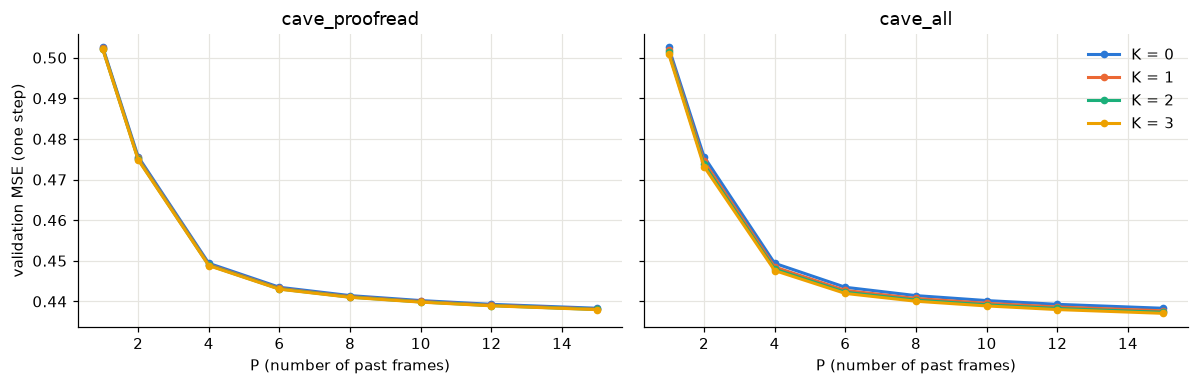

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, dataset in zip(axes, DATASETS):
    grid = pd.DataFrame(results[f'{dataset} / connectome']['grid'])
    for i, (K, g) in enumerate(grid.groupby('K')):
        ax.plot(g['P'], g['val_mse'], marker='o', markersize=4, color=['#2a78d6', '#eb6834', '#1baf7a', '#eda100'][i],
                label=f'K = {K}')
    ax.set(title=dataset, xlabel='P (number of past frames)')
axes[0].set_ylabel('validation MSE (one step)')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## Test results: G-VAR vs copy-last

The *improvement vs copy-last* column is $1 - \text{MSE}_\text{model} / \text{MSE}_\text{copy-last}$. Positive values mean the model beats copy-last.

In [5]:
ref = results['no graph']['test']   # baselines are scored on the same windows for every model
H = len(ref['copy_last']['mse'])
rows = {'copy_last': ref['copy_last'], 'mean': ref['mean']}
rows.update({f'G-VAR {n}': r['test']['gvar'] for n, r in results.items()})

table = pd.DataFrame({
    name: {'MSE h=1': m['mse'][0], 'Pearson h=1': m['pearson'][0],
           f'MSE h={H}': m['mse'][-1], f'Pearson h={H}': m['pearson'][-1],
           'improvement vs copy-last h=1': 1 - m['mse'][0] / ref['copy_last']['mse'][0],
           f'improvement vs copy-last h={H}': 1 - m['mse'][-1] / ref['copy_last']['mse'][-1]}
    for name, m in rows.items()}).T
table.style.format('{:.4f}')

,MSE h=1,Pearson h=1,MSE h=5,Pearson h=5,improvement vs copy-last h=1,improvement vs copy-last h=5
copy_last,0.6124,0.5984,1.3311,0.1093,0.0000,0.0000
mean,0.7930,0.0000,0.7875,0.0000,-0.2948,0.4084
G-VAR cave_proofread / connectome,0.4288,0.6634,0.7337,0.1840,0.2999,0.4488
G-VAR cave_all / connectome,0.4278,0.6642,0.7331,0.1857,0.3014,0.4493
G-VAR no graph,0.4292,0.6632,0.7341,0.1835,0.2993,0.4485
G-VAR cave_proofread / random,0.4291,0.6632,0.7340,0.1836,0.2993,0.4486
G-VAR cave_all / random,0.4288,0.6634,0.7339,0.1838,0.2998,0.4487


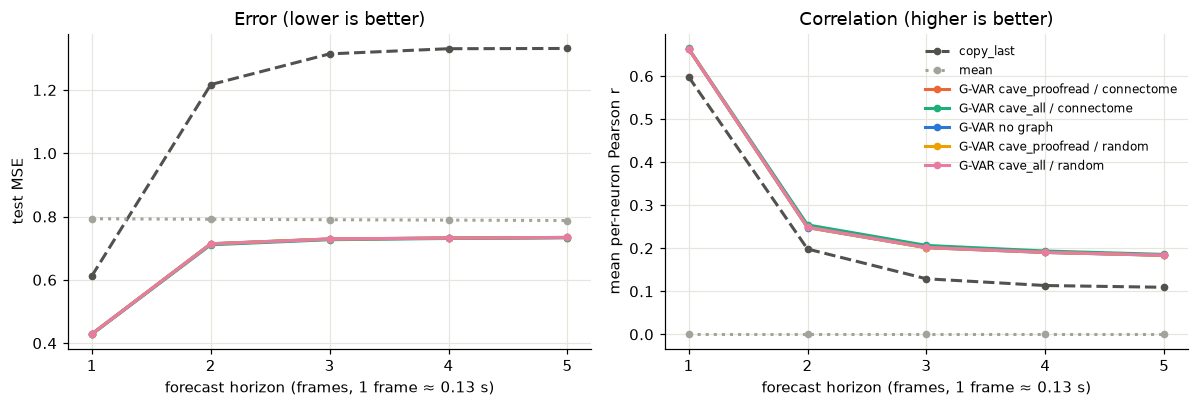

In [6]:
hs = np.arange(1, H + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for name, m in rows.items():
    key = name.removeprefix('G-VAR ')
    style = {'linestyle': '--'} if key == 'copy_last' else {'linestyle': ':'} if key == 'mean' else {}
    for ax, metric in ((ax1, 'mse'), (ax2, 'pearson')):
        ax.plot(hs, m[metric], color=COLORS[key], marker='o', markersize=4, label=name, **style)
ax1.set(xlabel='forecast horizon (frames, 1 frame ≈ 0.13 s)', ylabel='test MSE', title='Error (lower is better)')
ax2.set(xlabel='forecast horizon (frames, 1 frame ≈ 0.13 s)', ylabel='mean per-neuron Pearson r',
        title='Correlation (higher is better)')
for ax in (ax1, ax2):
    ax.set_xticks(hs)
ax2.legend(frameon=False, fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()

## The learned graph-time filter

Row $k$ is $\mathbf{h}_k$, the temporal filter applied to the $k$-hop graph signal $\mathbf{S}^k \mathbf{X}_t$. Row $k=0$ is each neuron's own history. Rows $k \geq 1$ are its presynaptic neighbourhood.

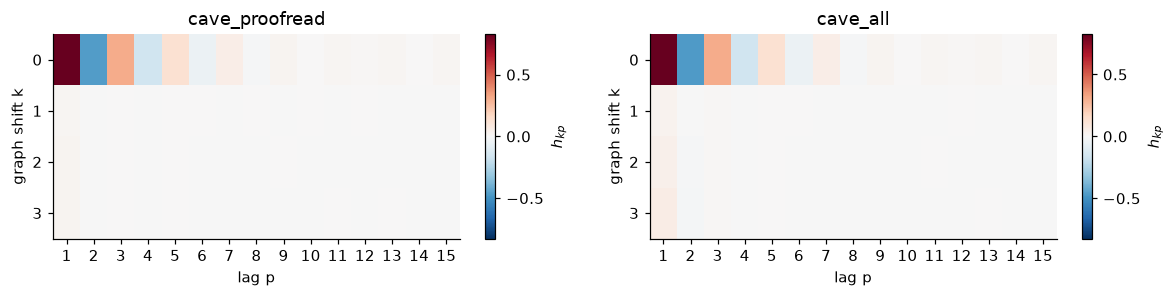

cave_proofread  sum of h_k over lags: [0.708 0.019 0.015 0.012]
cave_all        sum of h_k over lags: [0.705 0.026 0.023 0.036]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, dataset in zip(axes, DATASETS):
    h = np.array(results[f'{dataset} / connectome']['h'])
    lim = np.abs(h).max()
    im = ax.imshow(h, cmap='RdBu_r', vmin=-lim, vmax=lim, aspect='auto')
    ax.set_xticks(range(h.shape[1]), range(1, h.shape[1] + 1))
    ax.set_yticks(range(h.shape[0]))
    ax.set(title=dataset, xlabel='lag p', ylabel='graph shift k')
    ax.grid(False)
    fig.colorbar(im, ax=ax, label='$h_{kp}$')
plt.tight_layout()
plt.show()

for dataset in DATASETS:
    h = np.array(results[f'{dataset} / connectome']['h'])
    print(f"{dataset:15s} sum of h_k over lags:", np.round(h.sum(1), 3))

## Which neurons does the graph help?

Neurons without presynaptic partners only see the $k=0$ term, so the graph can only help neurons with inputs. Below is the per-neuron change in h=1 test MSE relative to the no-graph model, grouped by in-degree. Negative values mean the graph helps.

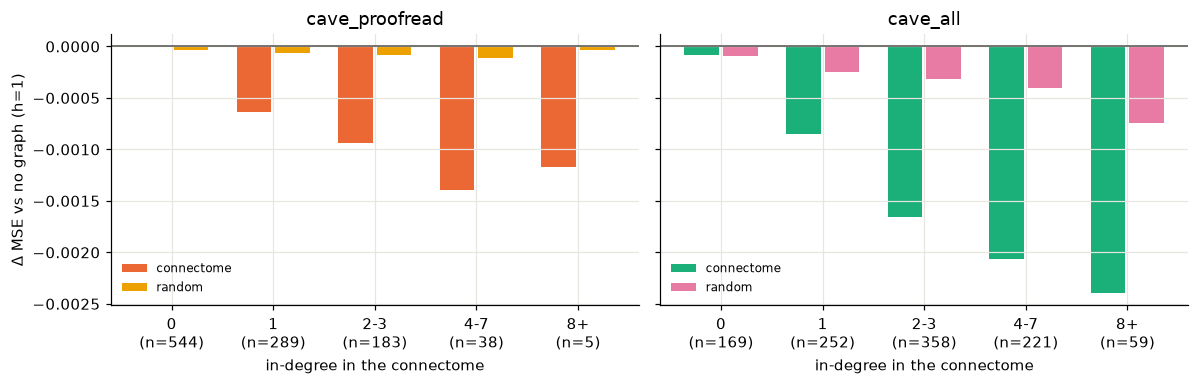

In [8]:
bins, labels = [0, 1, 2, 4, 8, np.inf], ['0', '1', '2-3', '4-7', '8+']
base = np.array(results['no graph']['test']['gvar']['mse_per_neuron_h1'])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, dataset in zip(axes, DATASETS):
    d = data[dataset]
    indeg = np.bincount(torch.load(f"{d['data_dir']}/edge_index.pt")[1].numpy(), minlength=d['X'].shape[1])
    group = pd.cut(indeg, bins, right=False, labels=labels)
    width = 0.38
    for i, graph in enumerate(('connectome', 'random')):
        name = f'{dataset} / {graph}'
        delta = np.array(results[name]['test']['gvar']['mse_per_neuron_h1']) - base
        # Random-graph neurons are grouped by their connectome in-degree, so this compares the same neurons
        g = pd.Series(delta).groupby(group, observed=False).mean()
        ax.bar(np.arange(len(labels)) + (i - 0.5) * width, g.values, width - 0.04, color=COLORS[name], label=graph)
    counts = pd.Series(group).value_counts().reindex(labels).fillna(0).astype(int)
    ax.set_xticks(np.arange(len(labels)), [f'{l}\n(n={c})' for l, c in zip(labels, counts)])
    ax.axhline(0, color='#52514e', linewidth=1)
    ax.set(title=dataset, xlabel='in-degree in the connectome')
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('Δ MSE vs no graph (h=1)')
plt.tight_layout()
plt.show()

## Notes and next steps

- **Shift operator.** `shift='adj'` uses raw synapse counts instead of the in-degree-normalised mean, and `undirected=True` also lets postsynaptic activity predict presynaptic activity.
- **Transfer.** The coefficients do not depend on $N$, so a model fitted with one connectome can be evaluated with the other by swapping $\mathbf{S}$.
- **Shared coefficients.** All neurons use the same $\mathbf{h}_k$, although their dynamics differ a lot. This is the price of having $P(K+1)$ parameters.
- **Nonlinear extension.** The natural next step is to put graph filters inside an RNN, GRU or LSTM.
- **The stimulus is not an input.** Much of the activity in visual cortex is driven by the video. Without it, the model only uses the recent past of the neurons.